# 04 — Distâncias, desigualdade de acesso e exploração da L3

Este notebook usa as **distâncias recalculadas para todos os setores**, os filtros e os quartis já definidos no plano. SUS é principal e todos os estabelecimentos são a robustez.

Vamos observar:

1. A distribuição das distâncias pela rua em cada capital, ponderada pela população.
2. As distribuições com distância relativa à média da capital, por quartil de renda.
3. O Gini da distância e as diferenças por renda e densidade.
4. A tabela densidade × renda, com quartis calculados **dentro de cada capital**.

A distribuição acumulada complementar é:

$$P(d\ge x)=\frac{\sum_{i:d_i\ge x}p_i}{\sum_i p_i}.$$

Ela responde: **qual fração da população mora a pelo menos esta distância do atendimento?** Cada setor recebe o peso de seus moradores. Distância é pela rede de carro; não é tempo nem descreve o meio de transporte efetivamente usado.

**Sobre leis de potência:** esta etapa apresenta as curvas em log-log. Não escolhemos automaticamente um limiar $x_{min}$ nem ajustamos γ a um trecho arbitrário. Uma curva desenhada não é um teste formal para aceitar ou rejeitar uma cauda de lei de potência. Qualquer ajuste posterior precisa de uma escolha de trecho discutida com a autora.


**Regra de distância adotada:** atribuímos cada setor à unidade que minimiza a soma da ligação setor–rua, da rota pela rede e da ligação unidade–rua. A comparação de favela foi adiada por decisão da autora e está fora desta análise.

In [1]:
from pathlib import Path
import sys
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PLANO.md").exists())
PROC = RAIZ / "dados" / "processados"
SAIDA = PROC / "analises" / "distancias"
FIG = RAIZ / "figuras" / "distancias"
SAIDA.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(RAIZ / "scripts"))
import estilo
estilo.aplicar()
def slug(nome):
    return unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode().split(" - ")[0].lower().replace(" ", "_")
capitais = pd.read_csv(PROC / "capitais_resumo.csv")
nome_capital = dict(zip(capitais.municipio.map(slug), capitais.municipio))

def media_ponderada(valores, pesos):
    return np.average(np.asarray(valores), weights=np.asarray(pesos))

def ccdf(valores, pesos):
    # Agrupar empates garante uma probabilidade única para cada distância.
    tabela = pd.DataFrame({"x": np.asarray(valores), "peso": np.asarray(pesos)})
    assert np.isfinite(tabela).all().all() and (tabela.peso >= 0).all()
    agrupada = tabela.groupby("x", sort=True).peso.sum()
    cauda = agrupada.iloc[::-1].cumsum().iloc[::-1] / agrupada.sum()
    return agrupada.index.to_numpy(), cauda.to_numpy()

def quantil_ponderado(valores, pesos, q):
    ordem = np.argsort(valores)
    x, w = np.asarray(valores)[ordem], np.asarray(pesos)[ordem]
    return x[np.searchsorted(np.cumsum(w), q*w.sum(), side="left")]

def gini_ponderado(valores, pesos):
    ordem = np.argsort(valores)
    x, w = np.asarray(valores)[ordem], np.asarray(pesos)[ordem]
    assert (x >= 0).all() and (w > 0).all()
    frac_pop = np.r_[0, np.cumsum(w)/w.sum()]
    frac_dist = np.r_[0, np.cumsum(x*w)/np.sum(x*w)]
    gini = 1-2*np.trapezoid(frac_dist, frac_pop)
    assert -1e-10 <= gini <= 1+1e-10
    return gini

def salvar(figura, nome):
    for extensao in ["png", "pdf"]:
        figura.savefig(FIG / f"{nome}.{extensao}")


## 1. Preparar os setores, os quartis e a distância relativa

A média de cada capital é ponderada pela população, usando todos os seus setores válidos:

$$\bar d_c=\frac{\sum_i p_i d_i}{\sum_i p_i}, \qquad \tilde d_i=d_i/\bar d_c.$$

Assim, distância relativa 1 é a média da própria capital. Juntar capitais por essa medida evita comparar diretamente seus tamanhos, mas o resultado conjunto ainda dá maior peso a capitais mais populosas.

Os quartis contêm aproximadamente o mesmo número de **setores com informação**, não o mesmo número de pessoas. São calculados por capital. Setores sem renda ficam fora dos grupos de renda, mas entram nas médias e curvas gerais.


In [2]:
setores, resumos, tabelas_calor = {}, [], {}
for versao, sufixo in [("SUS", "drive_sus"), ("Todos", "drive")]:
    partes = []
    for arquivo in sorted((PROC / "retomada" / "distancias").glob(f"*_{sufixo}_setores.csv")):
        d = pd.read_csv(arquivo, dtype={"CD_SETOR": str, "CO_CNES": str})
        d["capital"] = nome_capital[arquivo.name.removesuffix(f"_{sufixo}_setores.csv")]
        partes.append(d)
    bruto = pd.concat(partes, ignore_index=True)
    assert not bruto.CD_SETOR.duplicated().any()
    d = bruto.loc[(bruto.populacao > 0)&(bruto.ligacao_m <= 2000)&np.isfinite(bruto.d_m)].copy()
    assert (d.d_m > 0).all()
    d["q_renda"] = d.groupby("capital").renda_media.transform(lambda v: pd.qcut(v, 4, labels=[1,2,3,4]))
    d["q_densidade"] = d.groupby("capital").densidade.transform(lambda v: pd.qcut(v, 4, labels=[1,2,3,4]))
    d["media_capital_m"] = (
        (d.populacao*d.d_m).groupby(d.capital).transform("sum") /
        d.populacao.groupby(d.capital).transform("sum")
    )
    d["d_rel"] = d.d_m/d.media_capital_m
    for capital, cidade in d.groupby("capital"):
        np.testing.assert_allclose(media_ponderada(cidade.d_rel, cidade.populacao), 1)
        renda_q = {}
        for quartil in [1,2,3,4]:
            grupo = cidade.loc[cidade.q_renda == quartil]
            renda_q[quartil] = media_ponderada(grupo.d_m, grupo.populacao)/1000
        pop_antes = bruto.loc[(bruto.capital == capital)&(bruto.populacao > 0), "populacao"].sum()
        resumos.append({
            "versao": versao, "capital": capital, "n_setores": len(cidade),
            "populacao": cidade.populacao.sum(), "pop_excluida_pct": 100*(1-cidade.populacao.sum()/pop_antes),
            "dist_media_km": media_ponderada(cidade.d_m, cidade.populacao)/1000,
            "dist_mediana_km": quantil_ponderado(cidade.d_m.to_numpy(), cidade.populacao.to_numpy(), .5)/1000,
            "dist_p90_km": quantil_ponderado(cidade.d_m.to_numpy(), cidade.populacao.to_numpy(), .9)/1000,
            "gini_distancia": gini_ponderado(cidade.d_m.to_numpy(), cidade.populacao.to_numpy()),
            "dist_q1_renda_km": renda_q[1], "dist_q4_renda_km": renda_q[4],
            "razao_q1_q4": renda_q[1]/renda_q[4],
        })
    d.to_csv(SAIDA / f"setores_{versao.lower()}.csv", index=False)
    setores[versao] = d
    linhas_calor = []
    for (qd, qr), grupo in d.groupby(["q_densidade", "q_renda"], observed=True):
        linhas_calor.append({
            "q_densidade": int(qd), "q_renda": int(qr),
            "d_rel_media": media_ponderada(grupo.d_rel, grupo.populacao),
            "populacao": grupo.populacao.sum(), "n_setores": len(grupo)
        })
    tabelas_calor[versao] = pd.DataFrame(linhas_calor)
    tabelas_calor[versao].to_csv(SAIDA / f"densidade_renda_{versao.lower()}.csv", index=False)

resumo = pd.DataFrame(resumos)
resumo.to_csv(SAIDA / "resumo_capitais.csv", index=False)
display(resumo.loc[resumo.versao == "SUS", [
    "capital", "pop_excluida_pct", "dist_media_km", "dist_p90_km", "gini_distancia", "razao_q1_q4"
]].round(3))


,capital,pop_excluida_pct,dist_media_km,dist_p90_km,gini_distancia,razao_q1_q4
0,Belo Horizonte - MG,0.000,3.421,5.481,0.255,1.249
1,Belém - PA,3.378,3.748,6.670,0.337,2.003
2,Boa Vista - RR,1.447,5.708,9.806,0.348,0.816
3,Brasília - DF,0.017,6.786,14.483,0.402,0.450
4,Campo Grande - MS,0.230,3.271,4.952,0.344,1.523
5,Cuiabá - MT,0.608,4.533,8.128,0.362,1.169
6,Curitiba - PR,0.000,3.798,6.877,0.296,0.611
7,Florianópolis - SC,0.000,8.553,13.801,0.281,0.978
8,Fortaleza - CE,0.000,3.253,5.730,0.294,0.613
9,Goiânia - GO,0.000,5.442,10.770,0.356,1.700


## 2. L3: curvas por capital

Cada painel mostra uma capital na versão SUS. Os dois eixos são logarítmicos. Uma lei de potência exata em uma faixa produziria um segmento reto nessa faixa; curvas, cortes e mudanças de inclinação precisam ser observados antes de selecionar uma cauda.

O limite de uma amostra finita também causa queda no extremo. Portanto não usamos esse extremo sozinho como prova contra uma cauda de lei de potência.


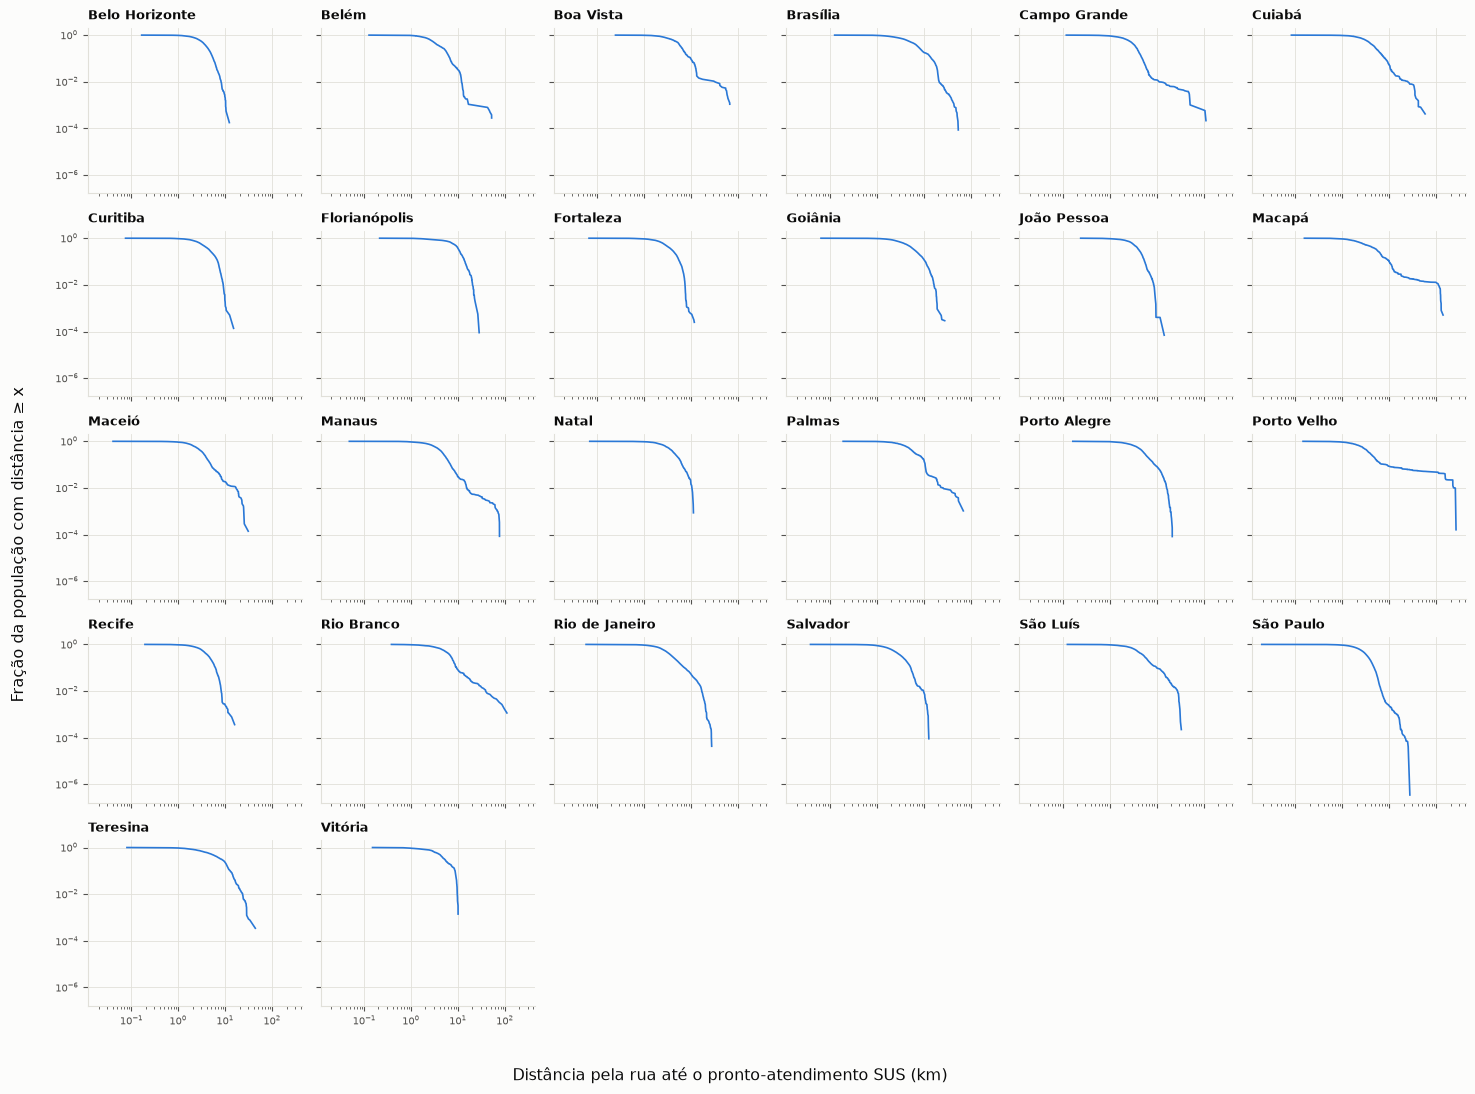

In [3]:
fig, eixos = plt.subplots(5, 6, figsize=(15, 11), sharex=True, sharey=True)
for ax, (capital, cidade) in zip(eixos.flat, setores["SUS"].groupby("capital", sort=True)):
    x, cauda = ccdf(cidade.d_m/1000, cidade.populacao)
    ax.plot(x, cauda, color=estilo.AZUL, linewidth=1.2)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(capital.split(" - ")[0], fontsize=9)
    ax.tick_params(labelsize=7)
for ax in eixos.flat[26:]:
    ax.set_visible(False)
fig.supxlabel("Distância pela rua até o pronto-atendimento SUS (km)")
fig.supylabel("Fração da população com distância ≥ x")
fig.tight_layout(rect=(.02,.02,1,1))
salvar(fig, "01_ccdf_26_capitais_sus")
plt.show()


## 3. Distância relativa por renda: juntando as capitais

Em cada painel, renda Q1 é o quarto de setores de menor renda **em sua capital**; Q4 é o de maior renda. As curvas são ponderadas pelos moradores dos setores com renda disponível.

Uma curva mais alta em uma distância relativa indica maior fração daquele grupo acima dessa distância. Curvas que se cruzam não permitem ordenar os grupos de forma única em todas as distâncias.

Esta figura descreve acesso por renda; a tabela da seção seguinte acrescenta o controle descritivo por quartis de densidade.


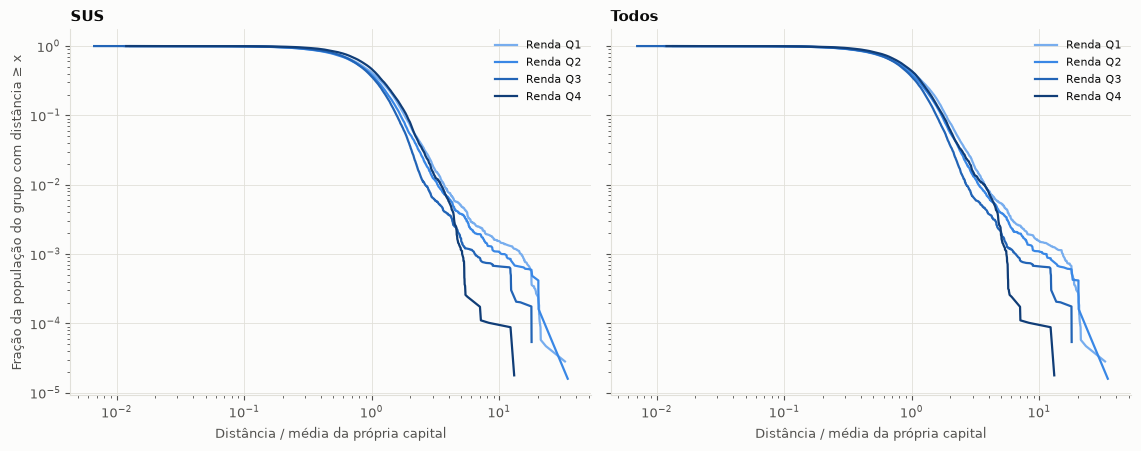

In [4]:
cores = [estilo.CMAP_AZUL(v) for v in [.3,.5,.7,.95]]
fig, eixos = plt.subplots(1, 2, figsize=(11.5, 4.6), sharex=True, sharey=True)
curvas_salvas = []
for ax, versao in zip(eixos, ["SUS", "Todos"]):
    for quartil, cor in zip([1,2,3,4], cores):
        grupo = setores[versao].loc[setores[versao].q_renda == quartil]
        x, cauda = ccdf(grupo.d_rel, grupo.populacao)
        ax.plot(x, cauda, color=cor, label=f"Renda Q{quartil}", linewidth=1.6)
        curvas_salvas.append(pd.DataFrame({"versao":versao, "q_renda":quartil, "d_rel":x, "ccdf":cauda}))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Distância / média da própria capital")
    ax.set_title(versao)
    ax.legend(fontsize=8)
eixos[0].set_ylabel("Fração da população do grupo com distância ≥ x")
fig.tight_layout()
salvar(fig, "02_ccdf_relativa_renda")
plt.show()
pd.concat(curvas_salvas, ignore_index=True).to_csv(SAIDA / "ccdf_relativa_renda.csv", index=False)


## 4. Densidade × renda: a tabela central de acesso

Cada célula mostra a distância relativa média ponderada pela população. **1 é a média da capital; acima de 1 significa mais longe que essa média.**

Os quartis são definidos por capital. Comparar colunas dentro de uma linha compara faixas de densidade, mas não mantém a densidade exatamente constante: são grupos amplos e a composição entre capitais ainda varia. A tabela é descritiva, sem interpretação causal.


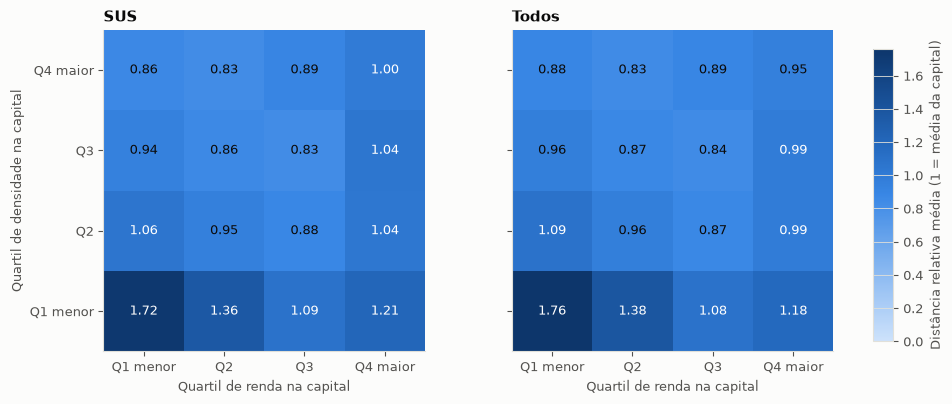

q_renda,1,2,3,4
q_densidade,,,,
1,1.721,1.359,1.087,1.215
2,1.059,0.946,0.876,1.039
3,0.938,0.857,0.830,1.042
4,0.864,0.829,0.889,0.995


In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
maior = max(t.d_rel_media.max() for t in tabelas_calor.values())
for ax, versao in zip(eixos, ["SUS", "Todos"]):
    matriz = tabelas_calor[versao].pivot(index="q_densidade", columns="q_renda", values="d_rel_media").reindex(
        index=[4,3,2,1], columns=[1,2,3,4])
    imagem = ax.imshow(matriz, cmap=estilo.CMAP_AZUL, vmin=0, vmax=maior, aspect="equal")
    for i in range(4):
        for j in range(4):
            valor = matriz.iloc[i,j]
            ax.text(j,i,f"{valor:.2f}", ha="center", va="center",
                    color="white" if valor > maior*.55 else estilo.TEXTO)
    ax.set_xticks(range(4), ["Q1 menor","Q2","Q3","Q4 maior"])
    ax.set_yticks(range(4), ["Q4 maior","Q3","Q2","Q1 menor"])
    ax.set_xlabel("Quartil de renda na capital")
    ax.set_title(versao)
    ax.grid(False)
eixos[0].set_ylabel("Quartil de densidade na capital")
fig.subplots_adjust(left=.10, right=.83, bottom=.17, top=.90, wspace=.27)
eixo_barra = fig.add_axes([.87,.20,.02,.65])
fig.colorbar(imagem, cax=eixo_barra, label="Distância relativa média (1 = média da capital)")
salvar(fig, "03_densidade_renda")
plt.show()
display(tabelas_calor["SUS"].pivot(index="q_densidade", columns="q_renda", values="d_rel_media").round(3))


## 5. Gini da distância

O Gini compara a distribuição da distância entre moradores: 0 corresponde a todos com a mesma distância; valores maiores indicam maior desigualdade da distância. Ele não mede se a cidade tem distâncias pequenas: uma cidade pode ter Gini baixo e todos morarem longe.

Cada morador recebe a distância de seu setor. A ponderação é por população e a integral da curva de Lorenz inclui a origem.


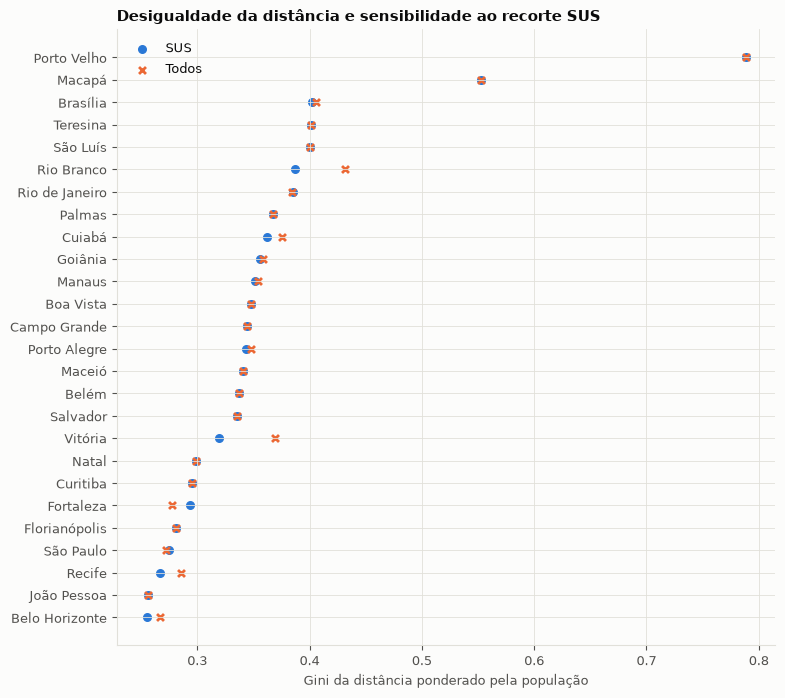

**Resultados descritivos SUS:** em **12 de 26** capitais, o Q1 de renda tem distância média menor que o Q4. Na faixa de menor densidade, a distância relativa é **1.72** para o Q1 de renda e **1.21** para o Q4. As comparações são descritivas e não demonstram causalidade.

271

In [6]:
gini = resumo.pivot(index="capital", columns="versao", values="gini_distancia").sort_values("SUS")
fig, ax = plt.subplots(figsize=(8.5, 8))
y = np.arange(len(gini))
ax.scatter(gini.SUS, y, color=estilo.AZUL, label="SUS", s=30)
ax.scatter(gini.Todos, y, color=estilo.LARANJA, label="Todos", s=25, marker="x")
ax.set_yticks(y, [c.split(" - ")[0] for c in gini.index])
ax.set_xlabel("Gini da distância ponderado pela população")
ax.set_title("Desigualdade da distância e sensibilidade ao recorte SUS")
ax.legend()
salvar(fig, "04_gini_capitais")
plt.show()

s = resumo.loc[resumo.versao == "SUS"]
n_mais_perto = int((s.razao_q1_q4 < 1).sum())
tab = tabelas_calor["SUS"].set_index(["q_densidade","q_renda"])
texto = (
    f"**Resultados descritivos SUS:** em **{n_mais_perto} de {len(s)}** capitais, "
    f"o Q1 de renda tem distância média menor que o Q4. "
    f"Na faixa de menor densidade, a distância relativa é "
    f"**{tab.loc[(1,1),'d_rel_media']:.2f}** para o Q1 de renda e "
    f"**{tab.loc[(1,4),'d_rel_media']:.2f}** para o Q4. "
    "As comparações são descritivas e não demonstram causalidade."
)
display(Markdown(texto))
(SAIDA / "interpretacao_distancias.md").write_text(texto+"\n",encoding="utf-8")


## 6. O que foi concluído e o que fica em aberto na L3?

As curvas, o Gini e a tabela densidade × renda foram recalculados com os dados corrigidos. Os resumos e as figuras antigos não devem substituir esses resultados.

**L3 descritiva aprovada pela autora em 04/11/2026:** apresentamos as curvas e o Gini, sem estimar γ ou escolher $x_{min}$. Não declaramos rejeição estatística de lei de potência pela visualização. Para um eventual estudo futuro de cauda seria necessário discutir e justificar seu início; ajustar a curva inteira por OLS não resolveria isso. O artigo mantém essa limitação explícita.

As curvas são ponderadas pela população. Se posteriormente for usado o estimador de Newman do plano, seu tamanho amostral será o número de setores da cauda, não o número de moradores; a relação entre a curva ponderada e o ajuste da amostra de setores também precisa ser explicada.

### Fontes e limites

- Newman, *Power laws, Pareto distributions and Zipf's law*, seção II: distribuição complementar, cauda e estimação do expoente. PDF em `Bibliografia/`.
- Xu et al. (2020), *Deconstructing laws of accessibility and facility distribution in cities*: distância na rede e desigualdade de acesso.
- [Planejamento](../planejamento.md), seções 6.1 e 7: quartis por capital, distância relativa e Gini.
- Mantêm-se os limites de coordenadas, setor reduzido a um ponto, rede de carro, efeito de borda, capacidade ignorada e renda como indicador agregado.
- Diferenças de distância não equivalem a diferenças de tempo, nem descrevem as alternativas reais de transporte de cada morador.

Todos os cálculos e gráficos estão neste notebook. Resultados em `dados/processados/analises/distancias/`; figuras em `figuras/distancias/`.
